1. Load the dataset
2. Created a function that cleans and prepare data (used in the final prediction on real data)
3. Prepare the data and cleaning up it for proccessing
5.



In [1]:
%reset -f

In [ ]:
# Load the dataset
from sklearn.preprocessing import LabelEncoder
import pandas as pd
le = LabelEncoder()
df = pd.read_csv('/sales.csv')
display(df.head())


,Unnamed: 0,store_ID,day_of_week,date,nb_customers_on_day,open,promotion,state_holiday,school_holiday,sales
0,425390,366,4,2013-04-18,517,1,0,0,0,4422
1,291687,394,6,2015-04-11,694,1,0,0,0,8297
2,411278,807,4,2013-08-29,970,1,1,0,0,9729
3,664714,802,2,2013-05-28,473,1,1,0,0,6513
4,540835,726,4,2013-10-10,1068,1,1,0,0,10882


In [3]:
def perform_data_cleanup(df):
  df_new = df.copy()
  # parse the date
  df_new["date"] = pd.to_datetime(df_new["date"], format="mixed")
  # sort by date
  df_new = df_new.sort_values(["date"])
  # remove empty rows with sales
  df_new = df_new[(df_new['open'] == 1)]
  # convert categorical data to features
  df_new['state_holiday'] = le.fit_transform(df_new['state_holiday'])
  return df_new



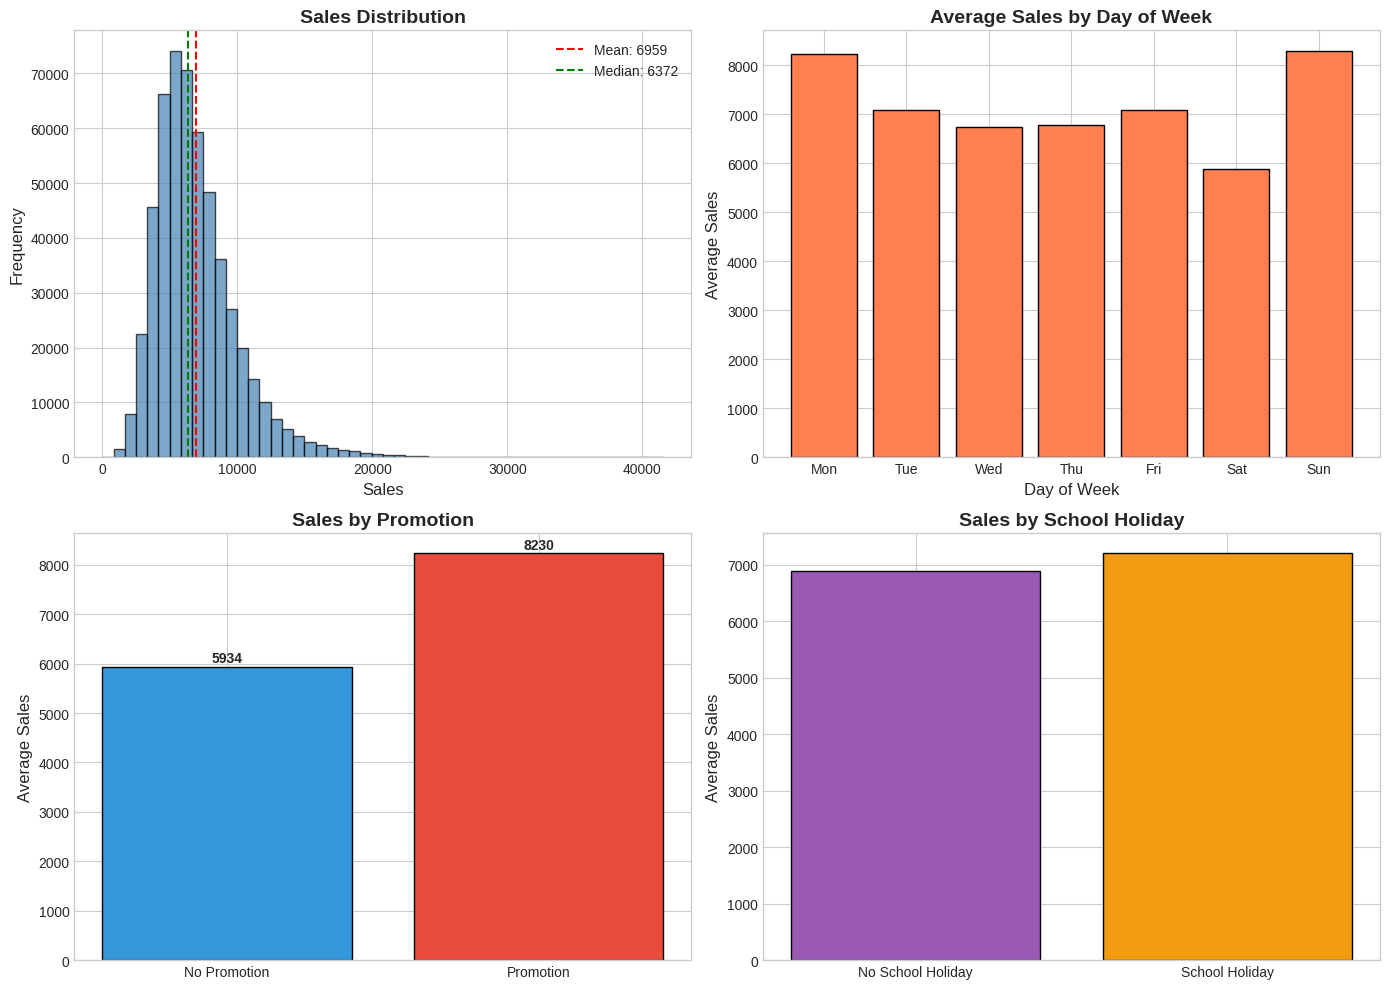

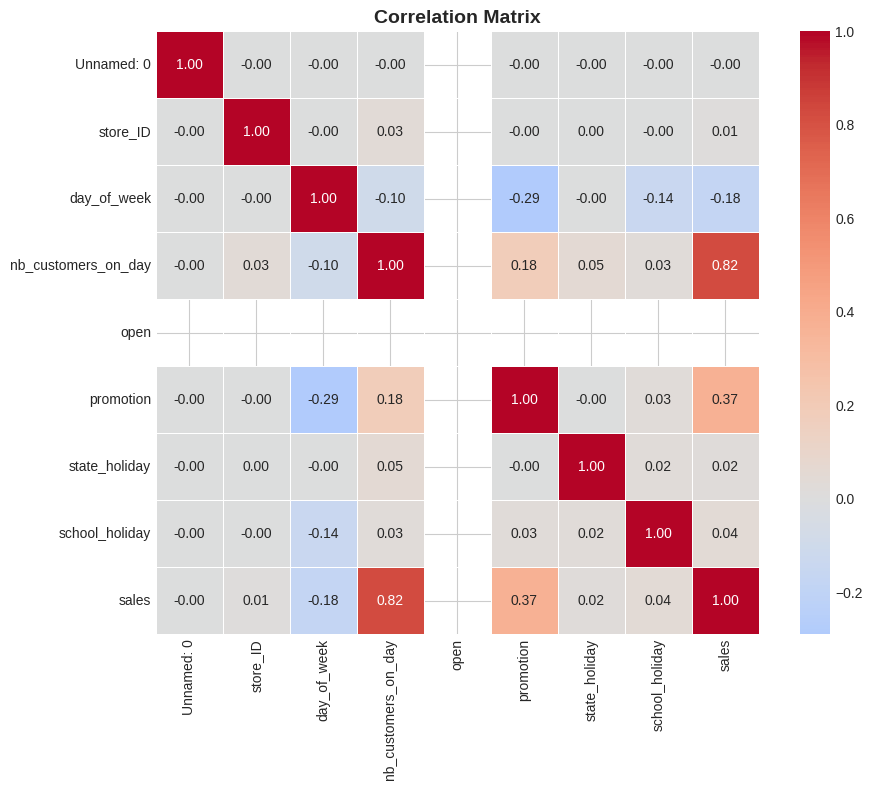

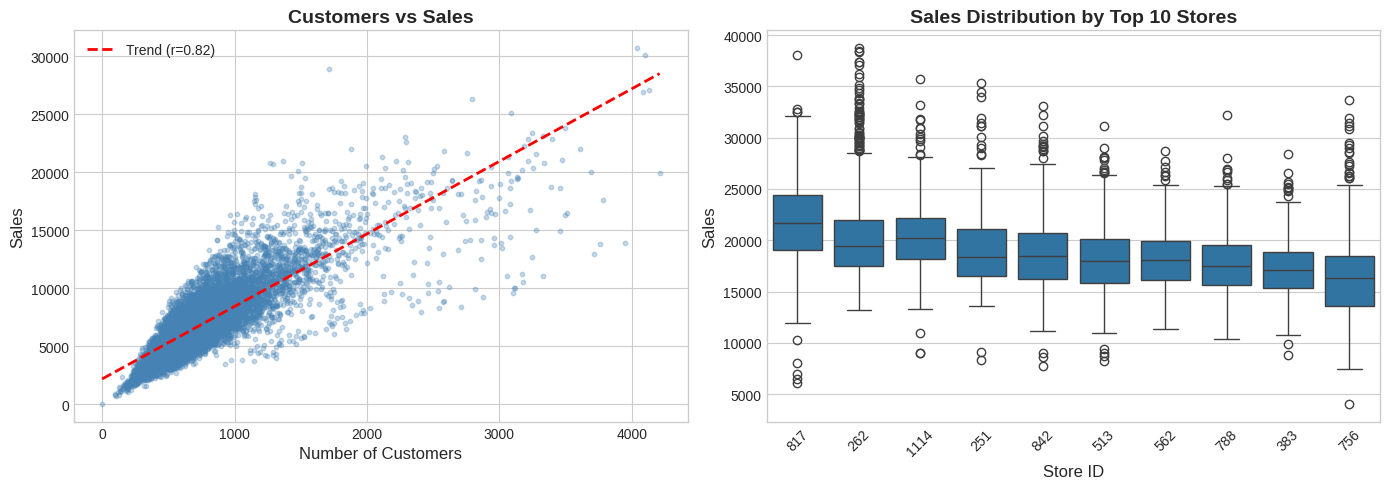

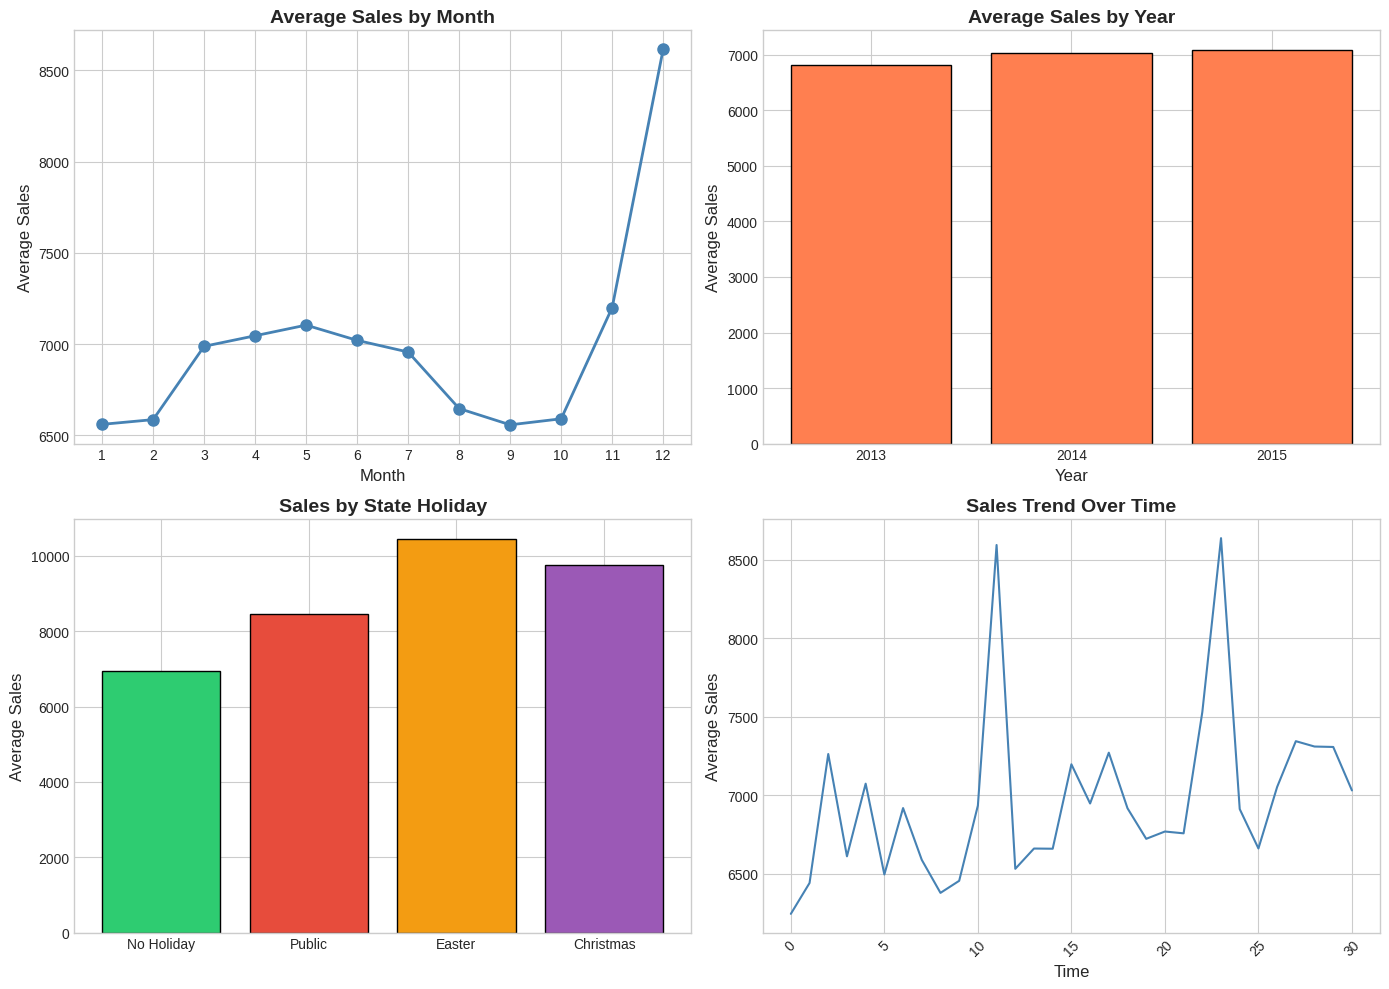

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# Reload clean data for EDA
df_clean = perform_data_cleanup(df.copy())
# Set style
plt.style.use('seaborn-v0_8-whitegrid')
# Figure 1: Sales Distribution Analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# 1.1 Sales Distribution
ax1 = axes[0, 0]
ax1.hist(df_clean['sales'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax1.axvline(df_clean['sales'].mean(), color='red', linestyle='--', label=f'Mean: {df_clean["sales"].mean():.0f}')
ax1.axvline(df_clean['sales'].median(), color='green', linestyle='--', label=f'Median: {df_clean["sales"].median():.0f}')
ax1.set_xlabel('Sales', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('Sales Distribution', fontsize=14, fontweight='bold')
ax1.legend()
# 1.2 Sales by Day of Week
ax2 = axes[0, 1]
day_sales = df_clean.groupby('day_of_week')['sales'].mean()
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
ax2.bar(range(1, 8), day_sales.values, color='coral', edgecolor='black')
ax2.set_xticks(range(1, 8))
ax2.set_xticklabels(days)
ax2.set_xlabel('Day of Week', fontsize=12)
ax2.set_ylabel('Average Sales', fontsize=12)
ax2.set_title('Average Sales by Day of Week', fontsize=14, fontweight='bold')
# 1.3 Sales by Promotion
ax3 = axes[1, 0]
promo_sales = df_clean.groupby('promotion')['sales'].mean()
ax3.bar(['No Promotion', 'Promotion'], promo_sales.values, color=['#3498db', '#e74c3c'], edgecolor='black')
ax3.set_ylabel('Average Sales', fontsize=12)
ax3.set_title('Sales by Promotion', fontsize=14, fontweight='bold')
for i, v in enumerate(promo_sales.values):
    ax3.text(i, v + 100, f'{v:.0f}', ha='center', fontweight='bold')
# 1.4 Sales by School Holiday
ax4 = axes[1, 1]
school_holiday_sales = df_clean.groupby('school_holiday')['sales'].mean()
ax4.bar(['No School Holiday', 'School Holiday'], school_holiday_sales.values, color=['#9b59b6', '#f39c12'], edgecolor='black')
ax4.set_ylabel('Average Sales', fontsize=12)
ax4.set_title('Sales by School Holiday', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
# Figure 2: Correlation Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
corr_matrix = df_clean[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f',
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
# Figure 3: Customers vs Sales Relationship
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax1 = axes[0]
sample = df_clean.sample(10000, random_state=42)
ax1.scatter(sample['nb_customers_on_day'], sample['sales'], alpha=0.3, s=10, c='steelblue')
ax1.set_xlabel('Number of Customers', fontsize=12)
ax1.set_ylabel('Sales', fontsize=12)
ax1.set_title('Customers vs Sales', fontsize=14, fontweight='bold')
# Add trend line
z = np.polyfit(sample['nb_customers_on_day'], sample['sales'], 1)
p = np.poly1d(z)
x_line = np.linspace(sample['nb_customers_on_day'].min(), sample['nb_customers_on_day'].max(), 100)
ax1.plot(x_line, p(x_line), "r--", linewidth=2, label=f'Trend (r={sample["nb_customers_on_day"].corr(sample["sales"]):.2f})')
ax1.legend()
# Box plot by store (top 10 stores)
ax2 = axes[1]
top_stores = df_clean.groupby('store_ID')['sales'].mean().nlargest(10).index
store_data = df_clean[df_clean['store_ID'].isin(top_stores)]
store_order = store_data.groupby('store_ID')['sales'].mean().sort_values(ascending=False).index
sns.boxplot(data=store_data, x='store_ID', y='sales', order=store_order, ax=ax2)
ax2.set_xlabel('Store ID', fontsize=12)
ax2.set_ylabel('Sales', fontsize=12)
ax2.set_title('Sales Distribution by Top 10 Stores', fontsize=14, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()
# Figure 4: Time-based Analysis
df_clean['date'] = pd.to_datetime(df_clean['date'])
df_clean['month'] = df_clean['date'].dt.month
df_clean['year'] = df_clean['date'].dt.year
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# Sales by Month
ax1 = axes[0, 0]
monthly_sales = df_clean.groupby('month')['sales'].mean()
ax1.plot(monthly_sales.index, monthly_sales.values, marker='o', linewidth=2, markersize=8, color='steelblue')
ax1.set_xlabel('Month', fontsize=12)
ax1.set_ylabel('Average Sales', fontsize=12)
ax1.set_title('Average Sales by Month', fontsize=14, fontweight='bold')
ax1.set_xticks(range(1, 13))
# Sales by Year
ax2 = axes[0, 1]
yearly_sales = df_clean.groupby('year')['sales'].mean()
ax2.bar(yearly_sales.index.astype(str), yearly_sales.values, color='coral', edgecolor='black')
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Average Sales', fontsize=12)
ax2.set_title('Average Sales by Year', fontsize=14, fontweight='bold')
# State Holiday Impact
ax3 = axes[1, 0]
holiday_sales = df_clean.groupby('state_holiday')['sales'].mean()
holiday_labels = ['No Holiday', 'Public', 'Easter', 'Christmas']
ax3.bar(holiday_labels, holiday_sales.values, color=['#2ecc71', '#e74c3c', '#f39c12', '#9b59b6'], edgecolor='black')
ax3.set_ylabel('Average Sales', fontsize=12)
ax3.set_title('Sales by State Holiday', fontsize=14, fontweight='bold')
# Sales Trend Over Time
ax4 = axes[1, 1]
df_clean['year_month'] = df_clean['date'].dt.to_period('M')
monthly_trend = df_clean.groupby('year_month')['sales'].mean()
ax4.plot(range(len(monthly_trend)), monthly_trend.values, linewidth=1.5, color='steelblue')
ax4.set_xlabel('Time', fontsize=12)
ax4.set_ylabel('Average Sales', fontsize=12)
ax4.set_title('Sales Trend Over Time', fontsize=14, fontweight='bold')
ax4.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [5]:
def comprehensive_feature_engineering(df):
    """
    Comprehensive feature engineering for improved model performance
    """
    df_fe = df.copy()

    # Parse date
    df_fe['date'] = pd.to_datetime(df_fe['date'])

    # ============ Date-based Features ============
    df_fe['year'] = df_fe['date'].dt.year
    df_fe['month'] = df_fe['date'].dt.month
    df_fe['day'] = df_fe['date'].dt.day
    df_fe['week_of_year'] = df_fe['date'].dt.isocalendar().week.astype(int)
    df_fe['day_of_year'] = df_fe['date'].dt.dayofyear
    df_fe['quarter'] = df_fe['date'].dt.quarter

    # ============ Cyclical Encoding for Time Features ============
    df_fe['month_sin'] = np.sin(2 * np.pi * df_fe['month'] / 12)
    df_fe['month_cos'] = np.cos(2 * np.pi * df_fe['month'] / 12)
    df_fe['day_of_week_sin'] = np.sin(2 * np.pi * df_fe['day_of_week'] / 7)
    df_fe['day_of_week_cos'] = np.cos(2 * np.pi * df_fe['day_of_week'] / 7)
    df_fe['day_sin'] = np.sin(2 * np.pi * df_fe['day'] / 31)
    df_fe['day_cos'] = np.cos(2 * np.pi * df_fe['day'] / 31)

    # ============ Binary/Flag Features ============
    df_fe['is_weekend'] = df_fe['day_of_week'].isin([6, 7]).astype(int)
    df_fe['is_month_start'] = df_fe['date'].dt.is_month_start.astype(int)
    df_fe['is_month_end'] = df_fe['date'].dt.is_month_end.astype(int)

    # ============ Store-level Aggregations ============
    store_avg_sales = df_fe.groupby('store_ID')['sales'].mean().to_dict()
    df_fe['store_avg_sales'] = df_fe['store_ID'].map(store_avg_sales)

    store_avg_customers = df_fe.groupby('store_ID')['nb_customers_on_day'].mean().to_dict()
    df_fe['store_avg_customers'] = df_fe['store_ID'].map(store_avg_customers)

    store_std_sales = df_fe.groupby('store_ID')['sales'].std().to_dict()
    df_fe['store_std_sales'] = df_fe['store_ID'].map(store_std_sales)

    # ============ Day-of-week Aggregations ============
    dow_avg_sales = df_fe.groupby('day_of_week')['sales'].mean().to_dict()
    df_fe['dow_avg_sales'] = df_fe['day_of_week'].map(dow_avg_sales)

    # ============ Promotion Interaction Features ============
    df_fe['promo_customers'] = df_fe['promotion'] * df_fe['nb_customers_on_day']
    df_fe['promo_weekend'] = df_fe['promotion'] * df_fe['is_weekend']

    # ============ Holiday Features ============
    df_fe['any_holiday'] = ((df_fe['state_holiday'] > 0) | (df_fe['school_holiday'] > 0)).astype(int)

    return df_fe


# Apply feature engineering
print("Applying feature engineering...")
df_fe = comprehensive_feature_engineering(df_clean)
print(f"Features created: {df_fe.shape[1]} columns")
print(f"New features added: {df_fe.shape[1] - df_clean.shape[1]}")
print("\nFeature columns:")
print(df_fe.columns.tolist())

Applying feature engineering...
Features created: 33 columns
New features added: 20

Feature columns:
['Unnamed: 0', 'store_ID', 'day_of_week', 'date', 'nb_customers_on_day', 'open', 'promotion', 'state_holiday', 'school_holiday', 'sales', 'month', 'year', 'year_month', 'day', 'week_of_year', 'day_of_year', 'quarter', 'month_sin', 'month_cos', 'day_of_week_sin', 'day_of_week_cos', 'day_sin', 'day_cos', 'is_weekend', 'is_month_start', 'is_month_end', 'store_avg_sales', 'store_avg_customers', 'store_std_sales', 'dow_avg_sales', 'promo_customers', 'promo_weekend', 'any_holiday']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')
# Define features to use
exclude_cols = ['sales', 'date', 'Unnamed: 0', 'state_holiday', 'year_month']
feature_cols = [col for col in df_fe.columns if col not in exclude_cols and df_fe[col].dtype in ['int64', 'float64', 'int32', 'float32']]
print(f"Using {len(feature_cols)} features:")
print(feature_cols)
# Prepare X and y
X_enhanced = df_fe[feature_cols].fillna(0)
y_enhanced = df_fe['sales']
# Split data
X_train_enh, X_test_enh, y_train_enh, y_test_enh = train_test_split(
    X_enhanced, y_enhanced, test_size=0.2, random_state=42
)
print(f"\nTraining set size: {len(X_train_enh)}")
print(f"Test set size: {len(X_test_enh)}")
# Dictionary to store results
results = {}
# ============ Linear Regression ============
print("\n" + "="*50)
print("Training Linear Regression...")
lr_model = LinearRegression()
lr_model.fit(X_train_enh, y_train_enh)
y_pred_lr = lr_model.predict(X_test_enh)
results['Linear Regression'] = {
    'RMSE': np.sqrt(mean_squared_error(y_test_enh, y_pred_lr)),
    'R2': r2_score(y_test_enh, y_pred_lr),
    'MAE': mean_absolute_error(y_test_enh, y_pred_lr)
}
print(f"RMSE: {results['Linear Regression']['RMSE']:.2f}, R2: {results['Linear Regression']['R2']:.4f}")
# ============ Decision Tree ============
print("\nTraining Decision Tree...")
dt_model = DecisionTreeRegressor(max_depth=15, min_samples_split=10, random_state=42)
dt_model.fit(X_train_enh, y_train_enh)
y_pred_dt = dt_model.predict(X_test_enh)
results['Decision Tree'] = {
    'RMSE': np.sqrt(mean_squared_error(y_test_enh, y_pred_dt)),
    'R2': r2_score(y_test_enh, y_pred_dt),
    'MAE': mean_absolute_error(y_test_enh, y_pred_dt)
}
print(f"RMSE: {results['Decision Tree']['RMSE']:.2f}, R2: {results['Decision Tree']['R2']:.4f}")
# ============ Random Forest ============
print("\nTraining Random Forest...")
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42
)
rf_model.fit(X_train_enh, y_train_enh)
y_pred_rf = rf_model.predict(X_test_enh)
results['Random Forest'] = {
    'RMSE': np.sqrt(mean_squared_error(y_test_enh, y_pred_rf)),
    'R2': r2_score(y_test_enh, y_pred_rf),
    'MAE': mean_absolute_error(y_test_enh, y_pred_rf)
}
print(f"RMSE: {results['Random Forest']['RMSE']:.2f}, R2: {results['Random Forest']['R2']:.4f}")


Using 28 features:
['store_ID', 'day_of_week', 'nb_customers_on_day', 'open', 'promotion', 'school_holiday', 'month', 'year', 'day', 'week_of_year', 'day_of_year', 'quarter', 'month_sin', 'month_cos', 'day_of_week_sin', 'day_of_week_cos', 'day_sin', 'day_cos', 'is_weekend', 'is_month_start', 'is_month_end', 'store_avg_sales', 'store_avg_customers', 'store_std_sales', 'dow_avg_sales', 'promo_customers', 'promo_weekend', 'any_holiday']

Training set size: 425612
Test set size: 106404

Training Linear Regression...
RMSE: 648.80, R2: 0.9565

Training Decision Tree...
RMSE: 594.02, R2: 0.9635

Training Random Forest...


In [ ]:
# =============================================================================
# MODEL COMPARISON & FEATURE IMPORTANCE
# =============================================================================
# Create results dataframe
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values('RMSE')
print("\n" + "="*60)
print("MODEL COMPARISON RESULTS (With Enhanced Features)")
print("="*60)
print(results_df)
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)
# Plot top 20 features
fig, ax = plt.subplots(figsize=(12, 8))
top_20 = feature_importance.head(20)
colors = plt.cm.viridis(np.linspace(0, 1, 20))
ax.barh(range(len(top_20)), top_20['importance'].values, color=colors)
ax.set_yticks(range(len(top_20)))
ax.set_yticklabels(top_20['feature'].values)
ax.invert_yaxis()
ax.set_xlabel('Importance', fontsize=12)
ax.set_title('Top 20 Feature Importance (Random Forest)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
r_data = pd.read_csv('./REAL_DATA.csv')

r_df = perform_data_cleanup(r_data)

r_y_pred_2 = model_2.predict(r_df[["nb_customers_on_day","promotion"]])

result = r_df.iloc




In [ ]:
r_df['predicted_sales'] = r_y_pred_2
display(r_df.head())

r_df.to_csv('./predicted_sales.csv', columns=["index", "predicted_sales"])